# 2024 YR4: an impact probability that rose to 3% and vanished

**The question.** On 27 December 2024 the ATLAS telescope in Chile (station W68) found a
small near-Earth asteroid, **2024 YR4**, two days after it had passed Earth. Within a week
its orbit showed a close pass on **22 December 2032**, and the chance that the pass would be
an impact was not zero. Over January and February 2025 that chance *rose* as more
observations arrived: about 1.3% at the end of January, 2.3% on 7 February, and **3.1% on
18 February** at NASA/JPL's Sentry system, the highest ever published for an object of its
size (~60 m). It reached Torino Scale 3. Then, within six days, it fell to almost nothing.
Attention moved to the **Moon**, whose impact probability climbed to about 4% by mid-2025.
In February 2026 the James Webb Space Telescope recovered the asteroid once more,
and that ruled the lunar impact out as well.

Why would a probability go *up* with better data, then collapse? The asteroid's possible
positions in December 2032 form a long, thin streak. Early on the streak is so long that
Earth covers a small part of it. As the arc grows, the streak shrinks; while it still
contains Earth, Earth covers a growing fraction, so the probability rises. Then the streak
shrinks to a length that no longer reaches Earth, and the probability drops to zero. This
is the normal course for an object that will eventually miss.

**What we do.** We replay it with PyRoOrb from the raw MPC astrometry:

1. cut the observations at a series of dates and fit an orbit to each set
   (`Observations.select`, `fit_orbit`);
2. draw thousands of orbits allowed by each fit (`sample_orbits`), integrate every one
   through December 2032 in the full force model (DE440 planets, the Moon, relativity), and
   find each one's closest approach to Earth and to the Moon (`OrbitEnsemble.close_approaches`);
3. count the clones that hit. The **impact probability** (IP) is the fraction that hit;
4. compare each number with the value NASA and ESA published at the time, and the final
   close approaches with JPL's.

This is a plain **Monte Carlo** estimate from the fit's covariance. It is not the method
Sentry uses: its current version, Sentry-II, searches the uncertainty region for impacting
orbits directly and reaches probabilities far below the 1/N of a plain sample. Differences are
discussed where they show.

In [1]:
import json
import urllib.request
import warnings
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Ellipse
from astropy.time import Time
import pyroorb

pyroorb.load_settings()       # the .env settings file (data folders), before the first fit

# Future UTC dates make astropy warn that leap seconds are not yet known; harmless here.
warnings.filterwarnings("ignore", message=".*dubious year.*")
plt.rcParams.update({"figure.figsize": (8, 4.5), "figure.dpi": 110, "axes.grid": True,
                     "grid.alpha": 0.3})
print("PyRoOrb", pyroorb.__version__)

PyRoOrb 0.9.1


## 1. The observations

`fetch_observations` returns everything the MPC holds today: the survey and follow-up
astrometry of December 2024 to March 2025, the JWST and large-telescope positions of
March–May 2025 (when the asteroid was already fading past magnitude 25), and the JWST
positions of February 2026.

In [2]:
obs = pyroorb.fetch_observations("2024 YR4")
jd = np.array([o["jd_utc"] for o in obs])
disc = next(o for o in obs if o.get("discovery"))
print(f"{len(obs)} optical observations from {len({o['obscode'] for o in obs})} stations, "
      f"{Time(jd.min(), format='jd').iso[:10]} to {Time(jd.max(), format='jd').iso[:10]}")
print(f"discovery: {Time(disc['jd_utc'], format='jd').iso[:16]} UTC, station {disc['obscode']}")

months = {}
for o in obs:
    m = Time(o["jd_utc"], format="jd").iso[:7]
    months[m] = months.get(m, 0) + 1
print("per month:", ", ".join(f"{m}: {n}" for m, n in sorted(months.items())))

before = [o for o in obs if o["jd_utc"] < disc["jd_utc"] - 0.3]
print(f"{len(before)} observations predate the discovery tracklet:",
      sorted({(o['obscode'], Time(o['jd_utc'], format='jd').iso[:10]) for o in before}))
print("JWST (station 274):", len([o for o in obs if o["obscode"] == "274"]), "observations")

512 optical observations from 63 stations, 2024-12-25 to 2026-02-26
discovery: 2024-12-27 05:42 UTC, station W68
per month: 2024-12: 125, 2025-01: 224, 2025-02: 137, 2025-03: 17, 2025-05: 1, 2026-02: 8
17 observations predate the discovery tracklet: [('703', '2024-12-26'), ('O38', '2024-12-26'), ('W68', '2024-12-25')]
JWST (station 274): 20 observations


The observations taken **before** the discovery tracklet are *precoveries*: detections found
afterwards in images that ATLAS, the Catalina Sky Survey (703) and station O38
had already taken on 25–26 December. They extend the arc by two days at its very start,
and section 4 shows that this matters a lot. MPC publication references (`ref`) show that
these, and some other early positions, were published in later batches than the
discovery observations.

So a cut by *observation date* is not exactly "what was known on that date": it can
contain precoveries found later, remeasured positions and late reports, and it lacks
nothing that was known then. Keep that in mind for every comparison below.

## 2. Replaying the arc: a fit at each date

We cut the observations at the start (00:00 UTC) of each date (and at noon on 20 February,
the morning after the night that cut the probability to 0.28%). The dates match those of
published Sentry values, plus one early one. `close_approaches` gives the nominal orbit's
2032 approach and its **linear** 1σ.

In [3]:
AU = 149_597_870.7          # km
cuts = ["2025-01-05", "2025-01-29", "2025-02-07", "2025-02-18", "2025-02-19",
        "2025-02-20 12:00", "2025-02-24", "2025-02-26", "2025-04-01", "2025-06-01", None]

def label(cut):
    return "all data" if cut is None else cut.replace(" 12:00", " noon")

def desc(cut):
    return "all data" if cut is None else f"data before {label(cut)}"

fits = {}
for cut in cuts:
    subset = obs if cut is None else obs.select(None, cut)
    fits[cut] = pyroorb.fit_orbit(subset, designation="2024 YR4")

print(f"{'data before':17s} {'obs':>4s} {'arc [d]':>8s} {'rms [\"]':>7s}   "
      f"2032 Earth approach (nominal ± 1σ, linear)")
for cut, f in fits.items():
    ca = pyroorb.close_approaches(f, "2032-12-12", "2033-01-02", max_distance=0.1)[0]
    print(f"{label(cut):17s} {f.n_observations():4d} {f.arc_length_days():8.1f} "
          f"{f.rms_residual():7.3f}   {ca['date_iso'][:16]} UTC  "
          f"{ca['distance_au'] * AU:10,.0f} ± {ca['sigma_distance_au'] * AU:9,.0f} km")

data before        obs  arc [d] rms ["]   2032 Earth approach (nominal ± 1σ, linear)
2025-01-05         169     10.0   0.201   2032-12-23 17:35 UTC   1,346,990 ± 1,287,605 km
2025-01-29         313     34.7   0.208   2032-12-22 11:37 UTC     121,329 ±   571,988 km


2025-02-07         391     43.0   0.200   2032-12-22 06:47 UTC     352,585 ±   321,135 km
2025-02-18         410     53.9   0.196   2032-12-22 08:31 UTC     269,646 ±   205,109 km
2025-02-19         413     54.9   0.196   2032-12-22 08:14 UTC     283,603 ±   192,566 km


2025-02-20 noon    440     57.0   0.191   2032-12-22 08:10 UTC     286,471 ±   119,252 km
2025-02-24         471     60.7   0.186   2032-12-22 08:24 UTC     275,601 ±    89,089 km
2025-02-26         475     61.9   0.186   2032-12-22 08:53 UTC     252,293 ±    84,506 km


2025-04-01         498     91.1   0.182   2032-12-22 08:41 UTC     261,633 ±    43,913 km
2025-06-01         499    137.6   0.181   2032-12-22 08:30 UTC     271,015 ±    30,626 km
all data           507    428.6   0.180   2032-12-22 08:21 UTC     277,464 ±     1,578 km


The nominal (best-fit) orbit never hits: it misses by 120,000 to 1.3 million km. What changes
is the uncertainty. With ten days of data the 1σ of the miss distance is more than a
million km, about 200 Earth radii; with all the data it is about 1,600 km. Whether Earth
lies *inside* the cloud of possible positions is a question about the whole cloud, not the
nominal orbit.

## 3. The impact probability by Monte Carlo

For each fit, `sample_orbits` draws clones from the fit's covariance; each is integrated
from the 2024 epoch to December 2032 in the same force model as the fit. The encounter is
non-linear, but the eight-year propagation of every clone is exact.

**When does a clone hit?** The integration includes Earth's gravity, so a clone's closest
approach *r*<sub>min</sub> already contains the gravitational focusing: an asteroid aimed
to pass at 8,000 km is pulled in to the surface. A clone hits when
*r*<sub>min</sub> < *R*<sub>⊕</sub> = 6,378 km.

The same criterion in the **target plane** (the b-plane, Öpik's formalism): take a
clone's incoming geocentric hyperbola, and its asymptote crosses the plane perpendicular to
the incoming velocity at a distance *b* from Earth's centre, the *impact parameter*. A
clone hits when

$$ b < b_\oplus = R_\oplus \sqrt{1 + v_\mathrm{esc}^2 / v_\infty^2}, $$

with *v*<sub>esc</sub> = 11.2 km/s at the surface and *v*<sub>∞</sub> ≈ 13 km/s for 2024 YR4.
Focusing enlarges Earth's cross-section by a factor (*b*<sub>⊕</sub>/*R*<sub>⊕</sub>)² ≈ 1.7.
We compute the hyperbola from each clone's state 0.1 days before its own closest approach
(two-body, Earth only), and its target-plane coordinates: ξ (the minimum distance between
the two orbits, which timing cannot change) and ζ (how early or late the asteroid arrives).
The two criteria are counted independently below; they should agree.

For the Moon the same, with *R*<sub>☾</sub> = 1,737 km, *v*<sub>esc</sub> = 2.4 km/s, and
the hyperbola taken one hour before the lunar approach.

About sixty lines of NumPy around the public API do all of this:

In [4]:
GM = {"earth": 398_600.435, "moon": 4_902.800}          # km^3/s^2
RADIUS = {"earth": 6_378.137, "moon": 1_737.4}          # km
N = 5000                                                # clones per fit
WINDOW = ("2032-12-12", "2033-01-02")

def hyperbola(rel, v_body, mu):
    # Target-plane coordinates of body-centred two-body hyperbolas.
    # rel: (m, 6) states relative to the body (au, au/day); v_body: (m, 3) the body's
    # heliocentric velocity, which fixes the zeta axis (Valsecchi et al. 2003 convention).
    r, v = rel[:, :3] * AU, rel[:, 3:] * AU / 86400.0               # km, km/s
    rn = np.linalg.norm(r, axis=1)
    v_inf = np.sqrt((v ** 2).sum(1) - 2 * mu / rn)
    h = np.cross(r, v); hn = np.linalg.norm(h, axis=1); h_hat = h / hn[:, None]
    e_vec = np.cross(v, h) / mu - r / rn[:, None]; e = np.linalg.norm(e_vec, axis=1)
    P = e_vec / e[:, None]; Q = np.cross(h_hat, P)
    S = P / e[:, None] + np.sqrt(1 - 1 / e ** 2)[:, None] * Q      # incoming asymptote
    b = hn / v_inf
    B = np.cross(S, h_hat) * b[:, None]
    xi_hat = np.cross(v_body, S); xi_hat /= np.linalg.norm(xi_hat, axis=1)[:, None]
    zeta_hat = np.cross(xi_hat, S)
    return {"xi": (B * xi_hat).sum(1), "zeta": (B * zeta_hat).sum(1), "b": b, "v_inf": v_inf}

def target_plane(ens, t_ca, body, lead):
    # Each clone's hyperbola from its state `lead` days before its own closest approach.
    step = lead / 4
    grid = np.arange(t_ca.min() - lead - step, t_ca.max() - lead + step, step)
    T = Time(grid, format="jd", scale="tdb")
    S, P = ens.propagate(T), pyroorb.body_states(body, T)
    k = np.clip(np.searchsorted(grid, t_ca - lead, side="right") - 1, 0, len(grid) - 1)
    tp = hyperbola(S[k, np.arange(len(t_ca))] - P[k], P[k, 3:], GM[body])
    tp["b_body"] = RADIUS[body] * np.sqrt(1 + 2 * GM[body] / (RADIUS[body] * tp["v_inf"] ** 2))
    return tp

def encounter(fit, ens, body, lead):
    # Every clone's closest approach to `body` in December 2032, and its target plane.
    nominal = min(pyroorb.close_approaches(fit, *WINDOW, body=body, max_distance=0.1),
                  key=lambda c: abs(c["jd_tdb"] - Time("2032-12-22").jd))
    # follow each clone +-6 linear sigma in time around the nominal (at least half a day)
    half = float(np.clip(6 * nominal["sigma_time_days"] + 0.25, 0.5, 8.0))
    ca = min(ens.close_approaches(*WINDOW, body=body, max_distance=0.1, half_window=half,
                                  chunk=100),
             key=lambda c: abs(c["nominal"]["jd_tdb"] - nominal["jd_tdb"]))
    out = {"nominal": nominal, "r_min": ca["distance_au"] * AU, "t_tdb": ca["jd_tdb"],
           "edge": ca["at_window_edge"]}
    out.update(target_plane(ens, ca["jd_tdb"], body, lead))
    out["hit"] = out["r_min"] < RADIUS[body]
    return out

def wilson(k, n, z=1.0):
    # Binomial interval (Wilson score; z=1 is 68%) for k hits in n clones.
    p = k / n
    c = (p + z * z / (2 * n)) / (1 + z * z / n)
    w = z * np.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / (1 + z * z / n)
    return max(c - w, 0.0), c + w

In [5]:
results = {}
for cut, f in fits.items():
    ens = pyroorb.sample_orbits(f, n=N, rng_seed=2024)
    results[cut] = {"earth": encounter(f, ens, "earth", 0.1),
                    "moon": encounter(f, ens, "moon", 1 / 24)}

print(f"{'data before':17s} {'Earth: hits':>11s} {'IP':>7s} {'68% range':>15s} {'b<b_E':>6s} "
      f"{'edge':>5s} | {'Moon: hits':>10s} {'IP':>7s} {'b<b_M':>6s}")
for cut, r in results.items():
    E, M = r["earth"], r["moon"]
    k, km = int(E["hit"].sum()), int(M["hit"].sum())
    lo, hi = wilson(k, N)
    print(f"{label(cut):17s} {k:11d} {k / N:7.2%} {lo:6.2%}–{hi:<7.2%} "
          f"{int((E['b'] < E['b_body']).sum()):6d} {int(E['edge'].sum()):5d} | "
          f"{km:10d} {km / N:7.2%} {int((M['b'] < M['b_body']).sum()):6d}")
print(f"\nzero hits in {N} clones: IP < {3 / N:.2%} (95%)")

data before       Earth: hits      IP       68% range  b<b_E  edge | Moon: hits      IP  b<b_M
2025-01-05                 13   0.26%  0.20%–0.34%       13     0 |          3   0.06%      3
2025-01-29                 63   1.26%  1.11%–1.43%       63     0 |          8   0.16%      8
2025-02-07                 78   1.56%  1.39%–1.75%       78     0 |         17   0.34%     17
2025-02-18                 52   1.04%  0.91%–1.19%       52     0 |         24   0.48%     24
2025-02-19                 51   1.02%  0.89%–1.17%       51     0 |         27   0.54%     27
2025-02-20 noon            11   0.22%  0.16%–0.30%       11     0 |         39   0.78%     39
2025-02-24                  0   0.00%  0.00%–0.02%        0     0 |         60   1.20%     60
2025-02-26                  3   0.06%  0.03%–0.11%        3     0 |         67   1.34%     67
2025-04-01                  0   0.00%  0.00%–0.02%        0     0 |        110   2.20%    110
2025-06-01                  0   0.00%  0.00%–0.02%        0

*Hits* counts clones whose integrated closest approach is inside the body; *b<b_E* counts
those whose impact parameter is inside the focused cross-section. They agree. *edge* counts
clones whose closest approach fell on the edge of the scanned time window (none, so no
impactor was missed for being early or late).

## 4. The probability against the published history

The published values, taken from NASA's Planetary Defense blog and the contemporary
NASA/ESA announcements: Sentry gave about 1.3% at the end of January 2025, **2.3%**
on 7 February, **3.1%** on 18 February (ESA's own system peaked at 2.8%), **1.5%** on
19 February, **0.28%** on 20 February and **0.004%** on 24 February. For the Moon: 1.7% at
the end of February, **3.8%** in early April (after JWST's March observations), **4.3%**
in June 2025 (after JWST's May observations), and **ruled out** in March 2026 (JWST,
February 2026; Sentry removed the object on 2026-03-05, see section 6).

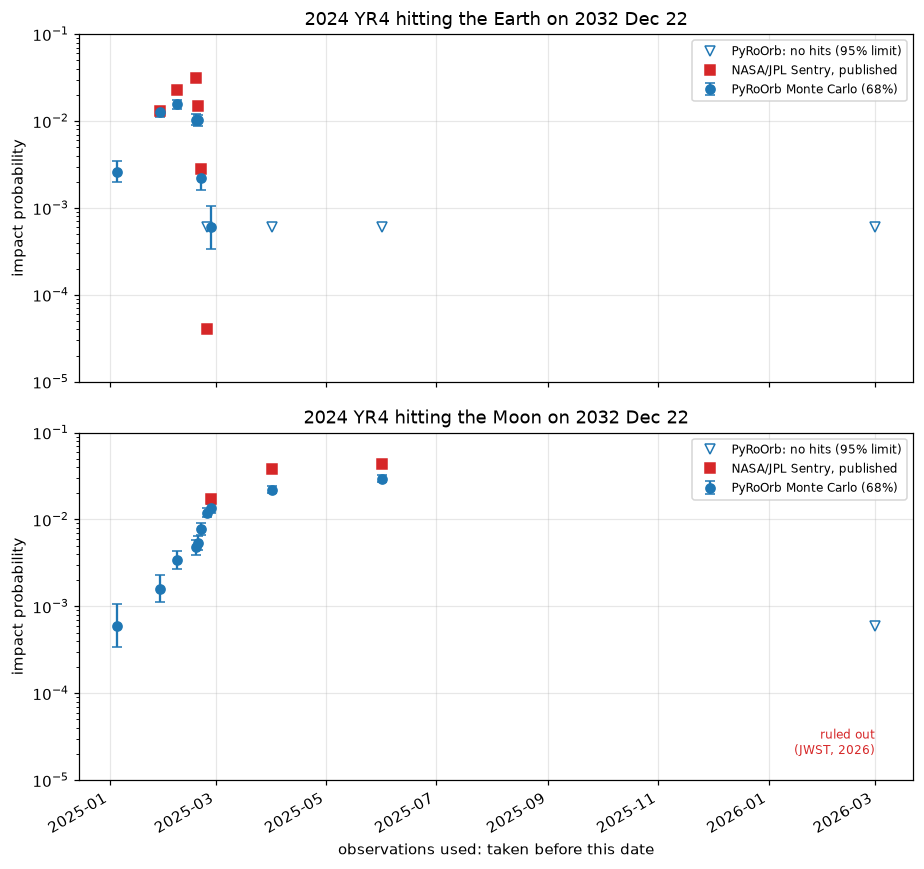

In [6]:
published_earth = {"2025-01-29": 0.013, "2025-02-07": 0.023, "2025-02-18": 0.031,
                   "2025-02-19": 0.015, "2025-02-20 12:00": 0.0028, "2025-02-24": 0.00004}
published_moon = {"2025-02-26": 0.017, "2025-04-01": 0.038, "2025-06-01": 0.043}

def when(cut):
    return Time("2026-03-01" if cut is None else cut).datetime

fig, axes = plt.subplots(2, 1, figsize=(8.5, 8), sharex=True)
for ax, body, published in ((axes[0], "earth", published_earth), (axes[1], "moon", published_moon)):
    for cut, r in results.items():
        k = int(r[body]["hit"].sum())
        if k:
            lo, hi = wilson(k, N)
            ax.errorbar(when(cut), k / N, yerr=[[k / N - lo], [hi - k / N]], fmt="o", c="C0",
                        capsize=3, label="PyRoOrb Monte Carlo (68%)")
        else:
            ax.plot(when(cut), 3 / N, "v", c="C0", mfc="none", label="PyRoOrb: no hits (95% limit)")
    for cut, p in published.items():
        ax.plot(when(cut), p, "s", c="C3", label="NASA/JPL Sentry, published")
    if body == "moon":
        ax.annotate("ruled out\n(JWST, 2026)", (when(None), 2e-5), color="C3", ha="right",
                    fontsize=8)
    handles, labels = ax.get_legend_handles_labels()
    keep = dict(zip(labels, handles))
    ax.legend(keep.values(), keep.keys(), fontsize=8, loc="upper right")
    ax.set(yscale="log", ylim=(1e-5, 0.1), ylabel="impact probability",
           title=f"2024 YR4 hitting the {'Earth' if body == 'earth' else 'Moon'} on 2032 Dec 22")
axes[1].set_xlabel("observations used: taken before this date")
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

**Reading the plot.** The shape of the story comes straight out of the raw astrometry. The
Earth probability rises from 0.26% on a ten-day arc to a peak of about 1.5% in late January
and early February. It falls by a factor of five with the nights of 19–20 February, and no
clone hits from 24 February on. The Moon's rises steadily the whole time, from 0.06% to 3%
in June 2025, and drops to zero once the February 2026 JWST positions are in.

Measured against what was published (± is the binomial 1σ):

| data before | PyRoOrb, Earth | Sentry, Earth | PyRoOrb, Moon | Sentry, Moon |
|---|---|---|---|---|
| 29 Jan 2025 | 1.26% ± 0.16 | ≈ 1.3% | 0.16% | |
| 7 Feb | 1.56% ± 0.18 | 2.3% | 0.34% | |
| 18 Feb | 1.04% ± 0.14 | **3.1%** | 0.48% | |
| 19 Feb | 1.02% ± 0.14 | 1.5% | 0.54% | |
| 20 Feb (noon) | 0.22% ± 0.07 | 0.28% | 0.78% | |
| 24 Feb | < 0.06% | 0.004% | 1.20% | |
| 26 Feb | 0.06% ± 0.04 | ≈ 0.001% | 1.34% ± 0.16 | 1.7% (late Feb) |
| 1 Apr | < 0.06% | | 2.20% ± 0.21 | 3.8% |
| 1 Jun | < 0.06% | | 2.96% ± 0.24 | 4.3% |
| all (to Feb 2026) | < 0.06% | removed | < 0.06% | ruled out |

The beginning and the end agree. The **peak does not**: our highest value is 1.56%, eleven
days before Sentry's 3.1%, and on 18 February we are a factor of three lower. The Moon
values are 20–40% lower than the published ones throughout. On 26 February our three hits
in 5,000 (0.06%) are well above Sentry's ~0.001%. This is the tail of a cloud that, as
section 7 shows, is wider than JPL's.

Sections 6 and 7 measure two things that probably account for most of the gap: the
precoveries at the start of the arc, and the weight given to the most precise positions.
Neither is a defect of the Monte Carlo; both concern which observations the orbit rests on.

## 5. The target plane: watching Earth leave the cloud

Each panel shows the clones' target-plane coordinates for one data cut. The horizontal axis
ζ is the *timing* direction (arriving earlier or later moves the crossing point along it);
the vertical axis ξ is the distance between the two orbits. Note the very different scales:
the cloud is hundreds of thousands of km long but only a few thousand km wide. The black
ellipse is Earth's focused cross-section (*b*<sub>⊕</sub> ≈ 8,400 km): a circle, stretched by
the unequal axes. Red: clones that hit Earth. Blue: clones that hit the Moon (the Moon is
not in this plane; it is where the clones that reach it six and a half hours later cross Earth's plane).

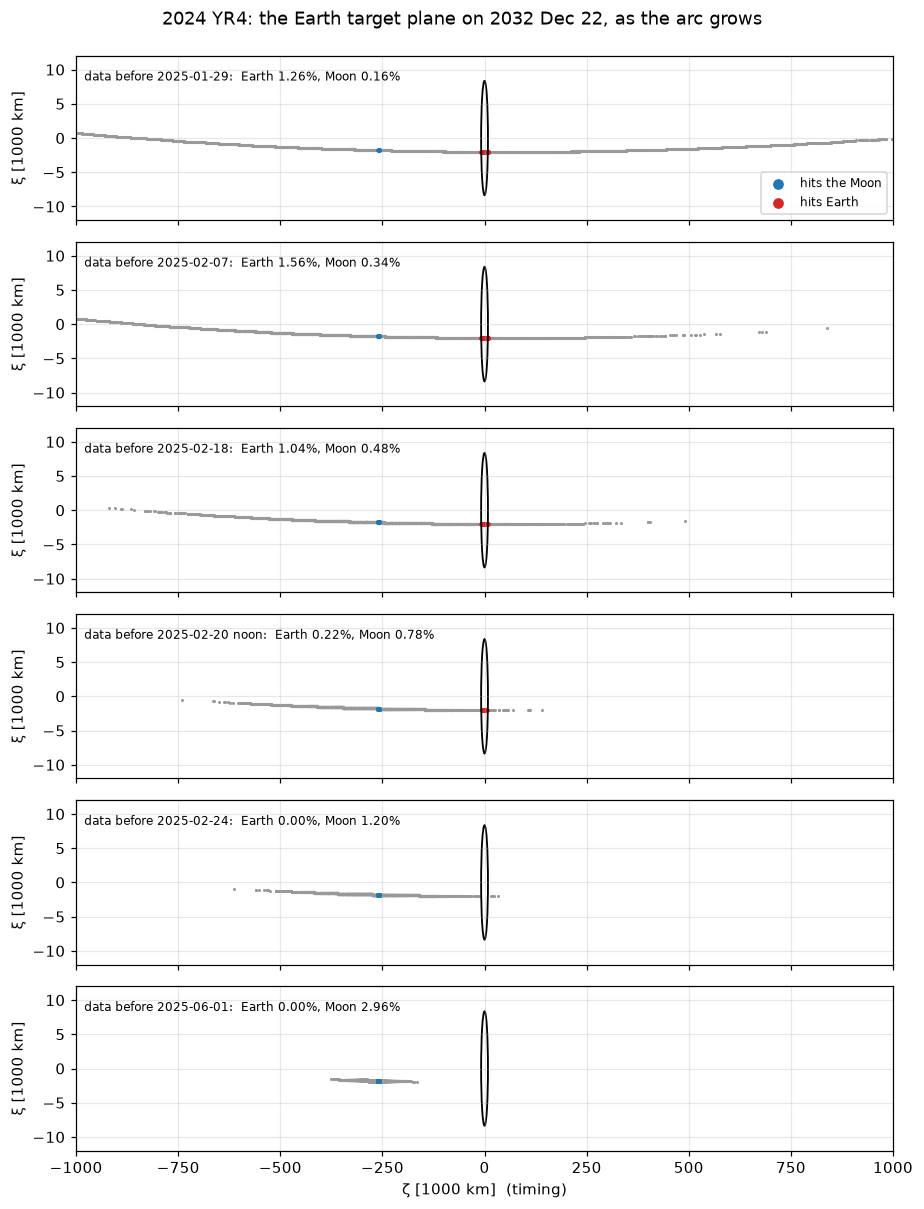

In [7]:
show = ["2025-01-29", "2025-02-07", "2025-02-18", "2025-02-20 12:00", "2025-02-24", "2025-06-01"]
fig, axes = plt.subplots(len(show), 1, figsize=(8.5, 11), sharex=True, sharey=True)
for ax, cut in zip(axes, show):
    E, M = results[cut]["earth"], results[cut]["moon"]
    z, x = E["zeta"] / 1e3, E["xi"] / 1e3                    # 1000 km
    ax.scatter(z, x, s=1, c="0.6", rasterized=True)
    ax.scatter(z[M["hit"]], x[M["hit"]], s=4, c="C0", label="hits the Moon")
    ax.scatter(z[E["hit"]], x[E["hit"]], s=4, c="C3", label="hits Earth")
    bE = np.median(E["b_body"]) / 1e3
    ax.add_patch(Ellipse((0, 0), 2 * bE, 2 * bE, fill=False, lw=1.2, color="k"))
    ax.text(0.01, 0.85, f"{desc(cut)}:  Earth {E['hit'].mean():.2%}, "
            f"Moon {M['hit'].mean():.2%}", transform=ax.transAxes, fontsize=8)
    ax.set_ylabel("ξ [1000 km]")
axes[0].legend(fontsize=8, loc="lower right", markerscale=3)
axes[-1].set_xlabel("ζ [1000 km]  (timing)")
axes[0].set(xlim=(-1000, 1000), ylim=(-12, 12))
fig.suptitle("2024 YR4: the Earth target plane on 2032 Dec 22, as the arc grows", y=0.995)
plt.tight_layout()
plt.show()

Each cloud is a thin streak along ζ. The observations fix the *geometry* of the orbit (ξ, to
a few hundred km) long before they fix the *timing*. The streak crosses Earth's axis at
ξ ≈ −2,000 km, well inside Earth's 8,400 km focused radius, so whether 2024 YR4 hit was
purely a question of whether it arrived at the right minute. In January the streak is
millions of km long and Earth covers a small slice of it. Through February it shrinks around
a point about 270,000 km from Earth, which is where the asteroid actually goes. While the
streak still reaches past Earth, Earth's slice of a shorter streak is a larger fraction, so
the probability climbs. Between 20 and 24 February the streak's end retreats past Earth's
disk and the probability collapses. The Moon impactors (blue, ζ ≈ −260,000 km) sit near the
middle of the streak, so the Moon's probability keeps rising long after Earth's has gone.
Only an arc much longer than any ground-based telescope could provide in 2025 shrinks the
streak enough to settle it; that came from JWST in February 2026.

## 6. How much did the precoveries matter?

The first two days of the arc (25–26 December, before discovery) were found and published
after the fact. Refit the data before 18 February (the published peak) without them:

In [8]:
first_night = disc["jd_utc"] - 0.3
for cut in ("2025-02-18",):
    for with_pre in (True, False):
        subset = obs.select(None if with_pre else first_night, cut)
        f = pyroorb.fit_orbit(subset, designation="2024 YR4")
        E = encounter(f, pyroorb.sample_orbits(f, n=N, rng_seed=2024), "earth", 0.1)
        k = int(E["hit"].sum()); lo, hi = wilson(k, N)
        print(f"data before {cut}, {'with' if with_pre else 'without':7s} the 25-26 Dec "
              f"precoveries: {len(subset):3d} obs, nominal miss "
              f"{E['nominal']['distance_au'] * AU:8,.0f} km, IP {k / N:.2%} ({lo:.2%}–{hi:.2%})")

data before 2025-02-18, with    the 25-26 Dec precoveries: 415 obs, nominal miss  269,646 km, IP 1.04% (0.91%–1.19%)


data before 2025-02-18, without the 25-26 Dec precoveries: 398 obs, nominal miss  135,183 km, IP 2.40% (2.19%–2.63%)


The 17 pre-discovery positions move the nominal 2032 miss from 135,000 to 270,000 km and
more than halve the probability on 18 February (2.40% without them, 1.04% with). Without
them our value is within a quarter of the 3.1% Sentry published that day.

That is not a proof that Sentry lacked them on 18 February: we do not know when JPL received
them. What it does show is that two days at the start of a 54-day arc moved the probability
by a factor of two. A replay is only as faithful as its reconstruction of the data available
at the time.

## 7. The Moon, and the final answer

With all the data, including JWST's February 2026 positions, we compare the closest approaches
with JPL's close-approach table (queried live) and with the published JWST result, and ask
JPL's Sentry what it says about the object today.

In [9]:
f = fits[None]
ours = {c["body"]: c for body in ("earth", "moon")
        for c in pyroorb.close_approaches(f, *WINDOW, body=body, max_distance=0.1)}
url = ("https://ssd-api.jpl.nasa.gov/cad.api?des=2024%20YR4&date-min=2032-12-01"
       "&date-max=2033-01-01&dist-max=0.05&body=ALL")
try:
    cad = json.load(urllib.request.urlopen(url, timeout=30))
    jpl = {row["body"].lower(): row for row in (dict(zip(cad["fields"], d)) for d in cad["data"])}
except Exception as ex:
    jpl = {}
    print("JPL close-approach API unavailable:", ex)

for body in ("earth", "moon"):
    c = ours[body]
    print(f"{body:5s} PyRoOrb  {c['date_iso'][:16]} UTC  {c['distance_au'] * AU:9,.0f} "
          f"± {c['sigma_distance_au'] * AU:5,.0f} km (1σ)")
    if body in jpl:
        j = jpl[body]
        sig = (float(j["dist_max"]) - float(j["dist_min"])) / 6 * AU     # CAD gives 3σ bounds
        print(f"{'':5s} JPL      {j['cd']} TDB  {float(j['dist']) * AU:9,.0f} "
              f"± {sig:5,.0f} km (1σ)   difference "
              f"{(c['distance_au'] - float(j['dist'])) * AU:+,.0f} km")
print("Moon, de Wit et al. (2026), JWST:      22,900 ±   800 km (1σ)")

try:
    sentry = json.load(urllib.request.urlopen(
        "https://ssd-api.jpl.nasa.gov/sentry.api?des=2024%20YR4", timeout=30))
    print("\nJPL Sentry today:", {k: v for k, v in sentry.items() if k != "signature"})
except Exception as ex:
    print("Sentry API unavailable:", ex)

earth PyRoOrb  2032-12-22 08:21 UTC    277,464 ± 1,578 km (1σ)
      JPL      2032-Dec-22 08:22 TDB    278,333 ±   724 km (1σ)   difference -869 km
moon  PyRoOrb  2032-12-22 14:57 UTC     22,009 ± 1,686 km (1σ)
      JPL      2032-Dec-22 14:57 TDB     22,938 ±   773 km (1σ)   difference -929 km
Moon, de Wit et al. (2026), JWST:      22,900 ±   800 km (1σ)

JPL Sentry today: {'removed': '2026-03-05 16:02:50', 'error': 'specified object removed'}


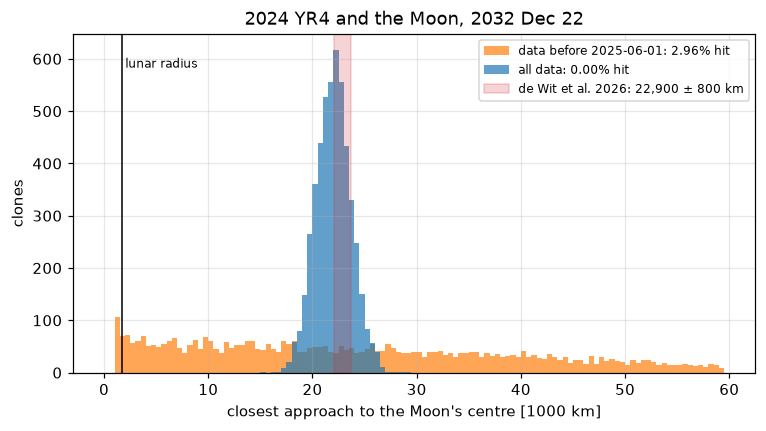

In [10]:
fig, ax = plt.subplots(figsize=(8, 4))
for cut, c in (("2025-06-01", "C1"), (None, "C0")):
    d = results[cut]["moon"]["r_min"]
    ax.hist(d / 1e3, bins=np.arange(0, 60, 0.5), color=c, alpha=0.7,
            label=f"{desc(cut)}: {results[cut]['moon']['hit'].mean():.2%} hit")
ax.axvline(RADIUS["moon"] / 1e3, c="k", lw=1)
ax.text(RADIUS["moon"] / 1e3 + 0.3, ax.get_ylim()[1] * 0.9, "lunar radius", fontsize=8)
ax.axvspan(22.1, 23.7, color="C3", alpha=0.2, label="de Wit et al. 2026: 22,900 ± 800 km")
ax.set(xlabel="closest approach to the Moon's centre [1000 km]", ylabel="clones",
       title="2024 YR4 and the Moon, 2032 Dec 22")
ax.legend(fontsize=8)
plt.show()

**The final answer agrees.** With all the data, PyRoOrb's two 2032 approaches are within
0.6 of our 1σ of JPL's: 869 km closer for Earth and 929 km for the Moon. PyRoOrb's Moon miss
(22,000 km from the centre) is 12 of our σ outside the lunar radius, and JWST's
22,900 ± 800 km (de Wit et al. 2026) is the same answer. No clone comes near.

Our formal **uncertainties are about twice JPL's** (1,580 and 1,690 km against 724 and
773 km). The next cell shows that this comes largely from how the JWST positions are
weighted.

The June 2025 histogram (orange) shows the situation the Moon probability came from: the
miss distance is spread almost evenly from 1,000 km to beyond 60,000 km, and 3% of it lies
inside the Moon. Nothing comes closer than about 1,000 km to the centre, because the streak
of possible positions crosses the Moon's target plane about 1,000 km from its centre. The
heap just above that is where the streak passes nearest the centre.

**How much do the JWST positions weigh?** They are reported with 0.1″ uncertainties, but
they fit our orbit far better than that. Here is what happens if we weight them at 0.02″
instead. This is a test of sensitivity, not a recommended setting:

In [11]:
for cut in ("2025-06-01", None):
    base = obs if cut is None else obs.select(None, cut)
    jw = [r for r in fits[cut].residuals() if r["obscode"] == "274"]
    rms = np.sqrt(np.mean([r["d_ra_arcsec"] ** 2 + r["d_dec_arcsec"] ** 2 for r in jw]) / 2)
    tight = pyroorb.Observations([dict(o, sigma_ra=0.02, sigma_dec=0.02) if o["obscode"] == "274"
                                  else o for o in base], base.meta)
    f2 = pyroorb.fit_orbit(tight, designation="2024 YR4")
    m1 = pyroorb.close_approaches(fits[cut], *WINDOW, body="moon", max_distance=0.1)[0]
    m2 = pyroorb.close_approaches(f2, *WINDOW, body="moon", max_distance=0.1)[0]
    print(f"{desc(cut)}: {len(jw)} JWST positions, rms residual {rms:.3f}\"")
    print(f"   weighted 0.1\"  : Moon miss {m1['distance_au'] * AU:7,.0f} ± {m1['sigma_distance_au'] * AU:6,.0f} km,"
          f" IP {results[cut]['moon']['hit'].mean():.2%}")
    line = (f"   weighted 0.02\" : Moon miss {m2['distance_au'] * AU:7,.0f} ± "
            f"{m2['sigma_distance_au'] * AU:6,.0f} km")
    if cut is not None:
        M2 = encounter(f2, pyroorb.sample_orbits(f2, n=N, rng_seed=2024), "moon", 1 / 24)
        line += f", IP {M2['hit'].mean():.2%}"
    print(line)

data before 2025-06-01: 12 JWST positions, rms residual 0.015"
   weighted 0.1"  : Moon miss  15,119 ± 32,706 km, IP 2.96%


   weighted 0.02" : Moon miss  22,210 ±  7,907 km, IP 0.44%


all data: 20 JWST positions, rms residual 0.013"
   weighted 0.1"  : Moon miss  22,009 ±  1,686 km, IP 0.00%
   weighted 0.02" : Moon miss  22,488 ±    538 km


The JWST positions fit at 0.013–0.015″ rms, about seven times better than their reported
0.1″. Weighting them at 0.02″ shrinks the final lunar uncertainty from 1,690 km to 540 km
(JPL: 773 km; de Wit et al.: 800 km), so JPL's weighting lies somewhere in between. With
the June 2025 data, though, the same change moves the nominal lunar miss from 15,000 to
22,000 km and cuts the Moon probability from 3.0% to 0.4%. JPL published **4.3%** from those
data, so JPL clearly did not weight the 2025 JWST positions that tightly. Twelve positions
from one telescope, with sigmas that are a matter of judgement, change a published impact
probability by a factor of seven. The 2026 JWST positions do not leave that freedom: the arc
to February 2026 rules out the impact at either weighting.

## Takeaways

* **The rise and fall is reproduced from the raw astrometry** in about 60 lines around the
  public API: `select` to cut the data, `fit_orbit`, `sample_orbits`,
  `OrbitEnsemble.close_approaches` and `propagate`. Earth's probability peaks at 1.6%
  (7 February) and is gone by 24 February; the Moon's climbs to 3% by June 2025 and goes to
  zero with JWST's 2026 data. The published sequence is 3.1% (18 February), ~0.001%, 4.3%,
  ruled out.
* **The rise was never a sign of danger.** It is what happens while a shrinking uncertainty
  streak still reaches past Earth. The target plane shows the geometry: the streak crosses
  Earth's disk, so timing alone decided, and the true arrival lies about 270,000 km away
  along the streak.
* **The size of the peak depends on the inputs**, not just the method. Two days of
  precoveries change the 18 February probability by a factor of two (1.0% with them, 2.4%
  without), and the weight given to twelve JWST positions changes the June 2025 Moon
  probability by a factor of seven (3.0% at their reported 0.1″, 0.4% at 0.02″).
* **The final orbit agrees with JPL's**: Earth and Moon 2032 approaches within 0.6σ
  (277,464 vs 278,333 km; 22,009 vs 22,938 km), and the lunar miss agrees with the
  published JWST result of 22,900 ± 800 km.

### Caveats

* **Monte Carlo has a floor.** With N = 5,000 clones the smallest non-zero probability is
  0.02%, and zero hits only says IP < 0.06% (95%). Sentry's 0.004% on 24 February is far
  below what this sample can resolve; the error bars in section 4 are binomial.
* **Linear sampling of a non-linear problem.** The clones are drawn from the fit's
  covariance at the fit's epoch (December 2024). On a ten-day arc the true set of allowed
  orbits is curved, and a Gaussian draw describes it only approximately.
* **Not the same data.** A cut by observation date includes precoveries, remeasurements and
  late reports that came after that date (section 6 measures how much the precoveries
  matter), and the data weighting and outlier rejection differ from JPL's and ESA's.
* **Force model.** Planets, the Moon and relativity (DE440), without the 16 large asteroids
  JPL includes, and without non-gravitational forces (JPL's solution has none either).
  Over eight years these matter at the kilometre level, far below the uncertainties here.
* **Earth's radius.** We use the equatorial radius, 6,378 km, without an atmosphere; adding
  ~100 km of atmosphere would raise the cross-section, and so the Earth IP, by about 2.5%.
* PyRoOrb also has research modules for impact probabilities and keyholes (used by the
  command line's `--impact` options). They have not been validated against Sentry, so this
  notebook does not use them: everything here is built from the public API.